# CS 179 Project — Bayesian Skill Estimation for StarCraft
Bradley-Terry latent skill model compared across SVI and MCMC (NUTS).

## 1. Imports & Setup

In [1]:
import numpy as np
import torch
import time
import matplotlib.pyplot as plt
import pyro
import pyro.infer
import pyro.optim
import pyro.distributions as dist
from IPython.display import clear_output

seed = 179
np.random.seed(seed)
pyro.set_rng_seed(seed)

/Applications/anaconda3/envs/cs179/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Loading

In [3]:
with open('data/train.csv') as f:
    lines = f.read().split('\n')

playerid = {}; p = 0
for line in lines:
    csv = line.split(',')
    if len(csv) != 10: continue
    for name in [csv[1], csv[4]]:
        if name not in playerid: playerid[name] = p; p += 1

nplayers = len(playerid)
playername = [''] * nplayers
for name, idx in playerid.items(): playername[idx] = name

pKeep, nEdge, nKeep = 1.0, 3, 5
nplays = np.zeros((nplayers, nplayers))
nwins  = np.zeros((nplayers, nplayers))

for line in lines:
    csv = line.split(',')
    if len(csv) != 10: continue
    a, b = playerid[csv[1]], playerid[csv[4]]
    aw, bw = csv[2] == '[winner]', csv[5] == '[winner]'
    if np.random.rand() < pKeep:
        if (nplays[a,b] < nKeep) and (
            (nplays[a,:]>0).sum() < nEdge or (nplays[:,b]>0).sum() < nEdge
        ):
            nplays[a,b] += 1; nplays[b,a] += 1
            nwins[a,b]  += aw; nwins[b,a]  += bw

pairs  = [(a, b) for a in range(nplayers) for b in range(a+1, nplayers) if nplays[a,b] > 0]
a_idx  = torch.tensor([p[0] for p in pairs], dtype=torch.long)
b_idx  = torch.tensor([p[1] for p in pairs], dtype=torch.long)
wins   = torch.tensor([nwins[p[0], p[1]]  for p in pairs], dtype=torch.float)
plays  = torch.tensor([nplays[p[0], p[1]] for p in pairs], dtype=torch.float)

print(f'Players: {nplayers} | Observed pairs: {len(pairs)} | Total games: {int(plays.sum())}')

Players: 999 | Observed pairs: 2988 | Total games: 4677


In [4]:
with open('data/valid.csv') as f:
    vlines = f.read().split('\n')

val_matches = []
for line in vlines:
    csv = line.split(',')
    if len(csv) != 10: continue
    p0, p1 = csv[1], csv[4]
    if p0 not in playerid or p1 not in playerid: continue
    a, b = playerid[p0], playerid[p1]
    winner = a if csv[2] == '[winner]' else b
    val_matches.append((a, b, winner))

print(f'Validation matches: {len(val_matches)}')

Validation matches: 94007


## 3. Model (Shared)

Each player $i$ has a latent skill $s_i \sim \mathcal{N}(0,1)$. Win probability is $\sigma(s_a - s_b)$, giving:
$$w_{ab} \sim \operatorname{Binomial}\!\left(n_{ab},\; \sigma(s_a - s_b)\right)$$
This same `model` function is used by both SVI and MCMC below.

In [6]:
pyro.get_param_store().clear()

def model(a_idx, b_idx, wins, plays, nplayers):
    with pyro.plate('players', nplayers):
        s = pyro.sample('s', dist.Normal(torch.zeros(nplayers), torch.ones(nplayers)))
    prob = torch.sigmoid(s[a_idx] - s[b_idx])
    with pyro.plate('matches', len(a_idx)):
        pyro.sample('obs', dist.Binomial(total_count=plays, probs=prob), obs=wins)

---
# Part A: Stochastic Variational Inference (SVI)

### A1. Guide (Mean-Field Variational Posterior)

Mean-field approximation: $q(s_i) = \mathcal{N}(\bar{s}_i, \sigma_i^2)$ with learnable $\bar{s}_i$ and $\sigma_i > 0$.

In [10]:
def guide(a_idx, b_idx, wins, plays, nplayers):
    s_mean = pyro.param('s_mean', torch.zeros(nplayers))
    s_std  = pyro.param('s_std',  0.1 * torch.ones(nplayers),
                         constraint=dist.constraints.positive)
    with pyro.plate('players', nplayers):
        pyro.sample('s', dist.Normal(s_mean, s_std))

_ = guide(a_idx, b_idx, wins, plays, nplayers)

### A2. Training

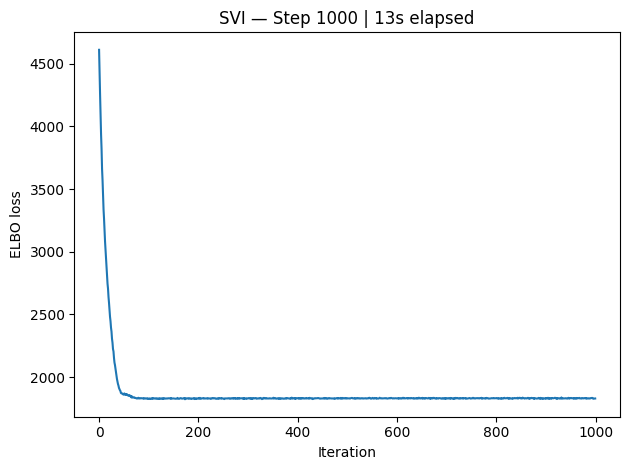

Step 1000: loss = 1828.84


In [11]:
pyro.set_rng_seed(seed)

optimizer = pyro.optim.Adam({'lr': 0.05})
svi = pyro.infer.SVI(model, guide, optimizer,
                     loss=pyro.infer.Trace_ELBO(num_particles=10))

niter  = 1000
losses = np.zeros(niter)
svi_time = time.time()

for step in range(niter):
    losses[step] = svi.step(a_idx, b_idx, wins, plays, nplayers)
    if (step + 1) % 100 == 0:
        clear_output(wait=True)
        plt.plot(losses[:step+1])
        plt.xlabel('Iteration'); plt.ylabel('ELBO loss')
        plt.title(f'SVI — Step {step+1} | {int(time.time()-svi_time)}s elapsed')
        plt.tight_layout(); plt.show()
        print(f'Step {step+1}: loss = {losses[step]:.2f}')

svi_time = time.time() - svi_time

### A3. Results

In [ ]:
svi_mean = pyro.param('s_mean').detach().numpy().copy()
svi_std  = pyro.param('s_std').detach().numpy().copy()

# Skill rankings
order = np.argsort(svi_mean)[::-1]
top_k = min(20, nplayers)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(top_k), svi_mean[order[:top_k]],
        xerr=svi_std[order[:top_k]], align='center',
        color='steelblue', alpha=0.8, ecolor='black', capsize=3)
ax.set_yticks(range(top_k))
ax.set_yticklabels([playername[i] for i in order[:top_k]])
ax.invert_yaxis()
ax.set_xlabel('Skill (posterior mean +/- 1 std)')
ax.set_title('SVI — Top Players by Estimated Skill')
plt.tight_layout(); plt.show()

# Validation accuracy
svi_correct = sum(
    (a if svi_mean[a] > svi_mean[b] else b) == winner
    for a, b, winner in val_matches
)
svi_acc = svi_correct / len(val_matches)
print(f'SVI validation accuracy: {svi_acc:.3f}  ({svi_correct}/{len(val_matches)})')
print(f'SVI runtime: {svi_time:.1f}s')
print(f'SVI mean posterior std: {svi_std.mean():.4f}')

---
# Part B: MCMC (NUTS)

### B1. Sampler Setup

In [19]:
class VerboseNUTS(pyro.infer.NUTS):
    """NUTS kernel that records mean acceptance rate every sample for plotting."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._sample_count = 0
        self.acceptance_history = []

    def sample(self, trace):
        result = super().sample(trace)
        self._sample_count += 1
        # _mean_accept_prob is a running mean maintained by the base NUTS class
        self.acceptance_history.append(self._mean_accept_prob)
        return result

nuts_kernel = VerboseNUTS(model, adapt_step_size=True, jit_compile=False)

mcmc = pyro.infer.MCMC(
    nuts_kernel,
    num_samples=500,
    warmup_steps=200,
    num_chains=1,
    disable_progbar=True,
)

### B2. Sampling

MCMC finished in 12.5s


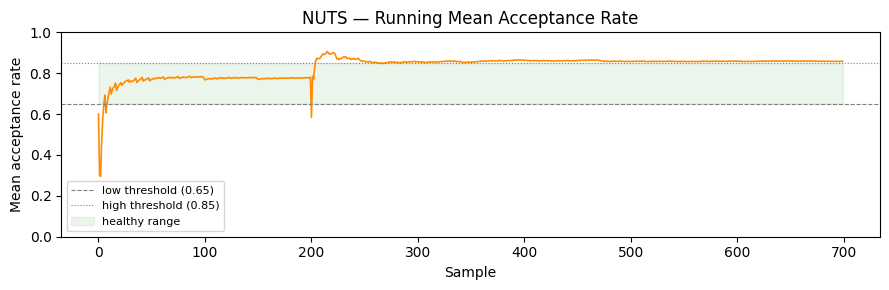

In [20]:
pyro.set_rng_seed(seed)
mcmc_time = time.time()

mcmc.run(a_idx, b_idx, wins, plays, nplayers)

mcmc_time = time.time() - mcmc_time
print(f'MCMC finished in {mcmc_time:.1f}s')

# Plot acceptance rate over samples
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(nuts_kernel.acceptance_history, lw=1.2, color='darkorange')
ax.axhline(0.65, color='grey', lw=0.8, ls='--', label='low threshold (0.65)')
ax.axhline(0.85, color='grey', lw=0.8, ls=':',  label='high threshold (0.85)')
ax.fill_between(range(len(nuts_kernel.acceptance_history)),
                0.65, 0.85, alpha=0.08, color='green', label='healthy range')
ax.set_xlabel('Sample'); ax.set_ylabel('Mean acceptance rate')
ax.set_title('NUTS — Running Mean Acceptance Rate')
ax.set_ylim(0, 1); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### B3. Results


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      s[0]      1.44      0.13      1.44      1.27      1.68    452.41      1.00
      s[1]      1.51      0.48      1.48      0.73      2.31    535.80      1.01
      s[2]      2.10      0.56      2.12      1.21      2.98    472.41      1.00
      s[3]      2.48      0.27      2.47      2.04      2.92    425.05      1.00
      s[4]      2.03      0.40      1.99      1.37      2.69    750.91      1.00
      s[5]      0.55      0.56      0.57     -0.32      1.53    723.78      1.00
      s[6]      1.52      0.38      1.52      0.97      2.16    310.51      1.00
      s[7]      0.52      0.56      0.55     -0.42      1.34    425.17      1.00
      s[8]      1.61      0.42      1.59      0.95      2.32    857.13      1.00
      s[9]      2.22      0.49      2.21      1.22      2.86    397.72      1.00
     s[10]      0.07      0.74      0.04     -1.12      1.32    498.96      1.00
     s[11]      0.83      0

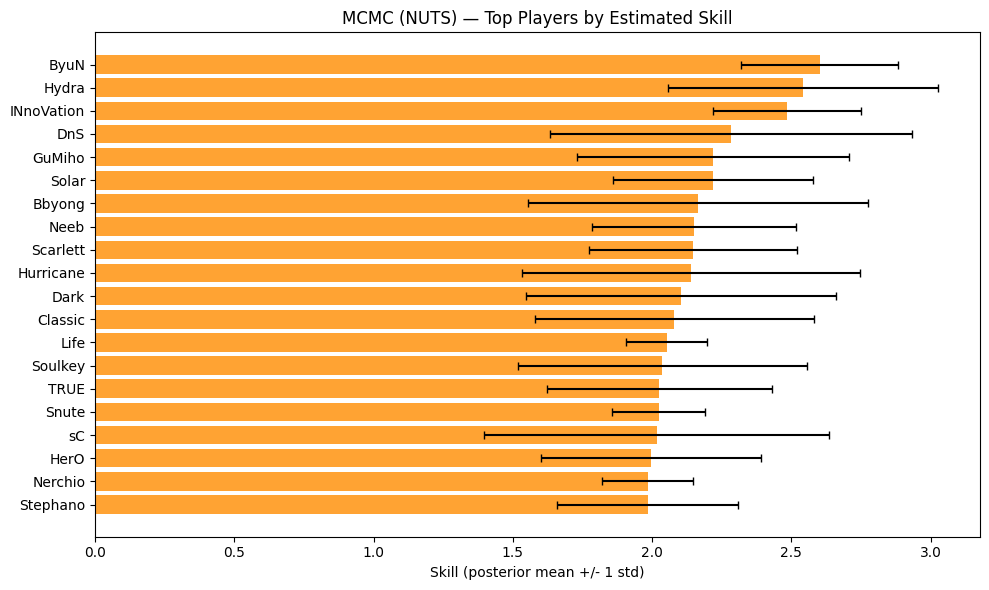

MCMC validation accuracy: 0.613  (57649/94007)
MCMC runtime: 12.5s
MCMC mean posterior std: 0.7775


In [21]:
samples = mcmc.get_samples()          # dict: 's' -> (num_samples, nplayers)
s_samples = samples['s'].numpy()      # (500, nplayers)

mcmc_mean = s_samples.mean(axis=0)
mcmc_std  = s_samples.std(axis=0)

# Diagnostics — effective sample size and R-hat (single chain: R-hat not meaningful,
# but ESS tells us whether 500 samples are sufficient)
try:
    summary = mcmc.summary(prob=0.9)
except Exception:
    pass  # summary printing is optional

# Skill rankings
order_m = np.argsort(mcmc_mean)[::-1]
top_k   = min(20, nplayers)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(top_k), mcmc_mean[order_m[:top_k]],
        xerr=mcmc_std[order_m[:top_k]], align='center',
        color='darkorange', alpha=0.8, ecolor='black', capsize=3)
ax.set_yticks(range(top_k))
ax.set_yticklabels([playername[i] for i in order_m[:top_k]])
ax.invert_yaxis()
ax.set_xlabel('Skill (posterior mean +/- 1 std)')
ax.set_title('MCMC (NUTS) — Top Players by Estimated Skill')
plt.tight_layout(); plt.show()

# Validation accuracy
mcmc_correct = sum(
    (a if mcmc_mean[a] > mcmc_mean[b] else b) == winner
    for a, b, winner in val_matches
)
mcmc_acc = mcmc_correct / len(val_matches)
print(f'MCMC validation accuracy: {mcmc_acc:.3f}  ({mcmc_correct}/{len(val_matches)})')
print(f'MCMC runtime: {mcmc_time:.1f}s')
print(f'MCMC mean posterior std: {mcmc_std.mean():.4f}')

---
# Part C: Comparison

In [ ]:
# Run after both parts are complete.
# Expects: svi_mean, svi_std, svi_acc, svi_time
#          mcmc_mean, mcmc_std, mcmc_acc, mcmc_time

print(f'{'Method':<10} {'Val Acc':>8} {'Runtime':>10} {'Mean Std':>10}')
print('-' * 42)
print(f'{'SVI':<10} {svi_acc:>8.3f} {svi_time:>9.1f}s {svi_std.mean():>10.4f}')
print(f'{'MCMC':<10} {mcmc_acc:>8.3f} {mcmc_time:>9.1f}s {mcmc_std.mean():>10.4f}')

In [ ]:
# Side-by-side skill ranking comparison (top 20)
order_svi  = np.argsort(svi_mean)[::-1][:top_k]
order_mcmc = np.argsort(mcmc_mean)[::-1][:top_k]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.barh(range(top_k), svi_mean[order_svi], xerr=svi_std[order_svi],
         align='center', color='steelblue', alpha=0.8, ecolor='black', capsize=3)
ax1.set_yticks(range(top_k))
ax1.set_yticklabels([playername[i] for i in order_svi])
ax1.invert_yaxis()
ax1.set_xlabel('Skill'); ax1.set_title('SVI')

ax2.barh(range(top_k), mcmc_mean[order_mcmc], xerr=mcmc_std[order_mcmc],
         align='center', color='darkorange', alpha=0.8, ecolor='black', capsize=3)
ax2.set_yticks(range(top_k))
ax2.set_yticklabels([playername[i] for i in order_mcmc])
ax2.invert_yaxis()
ax2.set_xlabel('Skill'); ax2.set_title('MCMC (NUTS)')

plt.suptitle('Posterior Skill Rankings: SVI vs MCMC', fontsize=13)
plt.tight_layout(); plt.show()